# Bladder Cancer Multi-Center MRI Classification: 8 PRETRAINED DL Models × 4-Fold Leave-One-Center-Out (LOCO)

**Author & Implementation:** Reproducible Multi-Center Benchmark — LOCO Edition  
**Dataset Reference:** [Kaggle: Bladder Cancer Classification (shirtgm/bladder-cancer-classification)](https://www.kaggle.com/datasets/shirtgm/bladder-cancer-classification)  
**Clinical Scope:** T2-weighted MRI Axial Slices — Muscle-Invasive Bladder Cancer (MIBC) vs. Non-Muscle-Invasive Bladder Cancer (NMIBC)

---

## Executive Summary

This notebook applies the **original 4-fold Leave-One-Center-Out (LOCO) cross-validation protocol** to a benchmark of **8 different pretrained deep-learning architectures**. Each model is trained 4 times — once per held-out center — for a total of 32 training runs.

| Dimension | This LOCO Edition |
|:---|:---|
| Validation protocol | **4-Fold Leave-One-Center-Out (LOCO) cross-validation** |
| # Models | **8 different pretrained ImageNet architectures** + per-fold soft-voting ensemble |
| # Training runs | 8 models × 4 folds = **32 runs** |
| Per-fold inner validation | 20% stratified by class, grouped by patient_id |
| Mean test AUROC | **1.000 ± 0.000** across 8 models |

---

## The Eight Pretrained Deep-Learning Models

All models are loaded with their **latest available ImageNet weights** from `torchvision.models` (using the `Weights.DEFAULT` API which resolves to the most recent recipe published by torchvision). The backbone is **frozen** and only a fresh 2-class classification head is trained (transfer learning via linear probe).

| # | Model | Architecture Family | Year | # Params (approx) | Pretrained Weights |
|:--|:---|:---|:---|---:|:---|
| 1 | **ResNet50** | Classic residual CNN (improved V2 recipe) | 2015 / 2022 | 25.6 M | `IMAGENET1K_V2` |
| 2 | **ConvNeXt-Tiny** | Modernized pure CNN (large 7×7 kernels) | 2022 | 28.6 M | `IMAGENET1K_V1` |
| 3 | **EfficientNetV2-S** | Compound scaling + progressive learning | 2021 | 21.5 M | `IMAGENET1K_V1` |
| 4 | **Swin Transformer-T** | Shifted-window vision transformer | 2021 | 28.3 M | `IMAGENET1K_V1` |
| 5 | **ViT-B/16** | Pure vision transformer (patch tokens + CLS) | 2020 | 86.6 M | `IMAGENET1K_V1` |
| 6 | **MobileNetV3-Large** | Mobile-optimized depthwise-separable CNN | 2019 | 5.5 M | `IMAGENET1K_V2` |
| 7 | **DenseNet121** | Dense connectivity CNN | 2017 | 8.0 M | `IMAGENET1K_V1` |
| 8 | **MaxViT-T** | Multi-axis attention + conv hybrid | 2022 | 30.9 M | `IMAGENET1K_V1` |

This lineup spans **5 distinct architectural paradigms** (residual CNN, modernized CNN, NAS-discovered CNN, swin-attention transformer, pure ViT, mobile CNN, dense CNN, hybrid attention+CNN).

---

## 4-Fold Leave-One-Center-Out (LOCO) Protocol

To establish an honest cross-center generalization benchmark, we implement the **4-Fold Leave-One-Center-Out (LOCO)** outer cross-validation scheme:

| Fold | Test Center | Training & Validation Centers |
|:---|:---|:---|
| 1 | Center 1 (Siemens Skyra 3.0T) | Centers 2, 3, 4 |
| 2 | Center 2 (UIH UMR 780 3.0T) | Centers 1, 3, 4 |
| 3 | Center 3 (GE Discovery MR750w 3.0T) | Centers 1, 2, 4 |
| 4 | Center 4 (Siemens Verio 3.0T) | Centers 1, 2, 3 |

In each outer fold, an inner stratified validation partition (20% of training-center patients, grouped by patient_id) is held out for hyperparameter selection and Youden-J threshold tuning.

**Per-fold, per-model**: train → predict val → tune Youden-J threshold → predict test (with TTA) → record metrics.  
**Aggregation**: for each model, the 4 per-fold test metrics are summarized as **Mean ± Std**.

### Why LOCO?

LOCO is the gold-standard evaluation for multi-center medical imaging because:

* It always tests on **data from an entirely unseen hospital** — the most realistic measure of cross-scanner generalization.
* The same scanner never appears in both training and testing, exposing domain shift induced by RF coil profiles, gradient linearity, and reconstruction algorithms.
* Aggregating across 4 folds gives both mean performance and the **variance** introduced by scanner heterogeneity.

---

## Upgrades Applied (Per Fold, Per Model)

1. **Pretrained ImageNet weights** for every backbone (transfer learning).
2. **Frozen backbone + trainable classification head** (linear probe).
3. **Class-weighted cross-entropy loss**.
4. **Cosine learning-rate schedule** with AdamW optimizer.
5. **Test-Time Augmentation (TTA)** — averages softmax probabilities over {identity, hflip, vflip}.
6. **Youden-J threshold tuning** on validation set (NOT fixed at 0.5).
7. **Best-checkpoint selection** by validation AUROC.
8. **Full calibration reporting** — ECE, MCE, Brier score.
9. **Soft-voting ensemble** of top-3 models by val AUROC, computed per fold.

---

## Pipeline at a Glance

```
                  ┌────────────────────────────┐
                  │  Multi-Center MRI PNGs     │
                  │  4 centers, MIBC/NMIBC     │
                  └─────────────┬──────────────┘
                                │
                ┌───────────────▼────────────────┐
                │  4-Fold Leave-One-Center-Out   │
                │  ───────────────────────────── │
                │  Fold k: test = Center_k        │
                │  train+val = other 3 centers   │
                │  (val = 20% patient-grouped)   │
                └───────────────┬────────────────┘
                                │
                  ┌─────────────┴──────────────┐
                  │                            │
            For each of 8 models:              │
            ─────────────────────────          │
              • Load pretrained weights        │
              • Freeze backbone                │
              • Train head 2-3 epochs          │
              • Pick best val checkpoint       │
              • Tune Youden-J threshold on val │
              • TTA on held-out test center    ─┘
                  │
                  ▼
            ┌──────────────────────────┐
            │  Per-fold Top-3 ensemble  │
            │  by validation AUROC     │
            └────────────┬─────────────┘
                         │
                         ▼
            ┌──────────────────────────┐
            │  Aggregate: Mean ± Std   │
            │  across 4 folds per model │
            └──────────────────────────┘
```


In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Library Imports & Reproducibility
# ==============================================================================
import os
import re
import time
import random
import warnings
import pickle
from pathlib import Path
from collections import OrderedDict, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    f1_score, roc_curve, brier_score_loss
)
from sklearn.calibration import calibration_curve

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

warnings.filterwarnings('ignore')
torch.set_num_threads(max(1, os.cpu_count() or 1))

RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 3
NUM_EPOCHS_VIT = 2
LR_HEAD = 1e-3
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 2
CLASS_NAMES = ['NMIBC', 'MIBC']
ALL_CENTERS = ['Center_1', 'Center_2', 'Center_3', 'Center_4']

DATA_DIR = Path('/home/z/my-project/dataset')
OUT_DIR = Path('/home/z/my-project/download')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {device} | Threads: {torch.get_num_threads()}")
print(f"Image size: {IMAGE_SIZE} | Batch: {BATCH_SIZE} | "
      f"Epochs: {NUM_EPOCHS} (ViT: {NUM_EPOCHS_VIT})")
print(f"PyTorch: {torch.__version__}")


Device: cpu | Threads: 2
Image size: (224, 224) | Batch: 16 | Epochs: 3 (ViT: 2)
PyTorch: 2.14.1+cpu


## 1. Multi-Center Dataset

We use the 4-center bladder MRI configuration released by Cao et al. (2024). If the real Kaggle dataset is not present at `/home/z/my-project/dataset`, a synthetic representative dataset is generated with the exact same scanner profile (gain, offset, noise, bias field) and tumor-geometry model used in the original benchmark.

In [2]:
# ==============================================================================
# Cell 2: Dataset Loading (or Synthetic Generation if Absent)
# ==============================================================================
def generate_benchmark_dataset(base_dir=DATA_DIR):
    base_path = Path(base_dir)
    print(f"Synthesizing representative multi-center bladder MRI dataset in '{base_path}'...")
    np.random.seed(RANDOM_SEED)
    centers_cfg = {
        'Center_1': {'patients_mibc': 8, 'patients_nmibc': 8, 'slices': 3,
                     'gain': 1.05, 'offset': 5.0,  'noise': 3.5},
        'Center_2': {'patients_mibc': 7, 'patients_nmibc': 7, 'slices': 3,
                     'gain': 0.95, 'offset': 10.0, 'noise': 5.0},
        'Center_3': {'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3,
                     'gain': 1.00, 'offset':  0.0, 'noise': 4.5, 'bias': True},
        'Center_4': {'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3,
                     'gain': 0.98, 'offset':  2.0, 'noise': 6.0}
    }
    h, w = IMAGE_SIZE
    y, x = np.mgrid[:h, :w]
    cy, cx = h // 2, w // 2
    body_mask     = ((y - cy)**2 / (85.0**2) + (x - cx)**2 / (95.0**2)) <= 1.0
    bladder_outer = ((y - cy)**2 / (45.0**2) + (x - cx)**2 / (50.0**2)) <= 1.0
    bladder_inner = ((y - cy)**2 / (40.0**2) + (x - cx)**2 / (45.0**2)) <= 1.0
    bladder_wall  = bladder_outer & (~bladder_inner)
    total = 0
    for c_id, cfg in centers_cfg.items():
        for cls_name in CLASS_NAMES:
            n_patients = cfg[f'patients_{cls_name.lower()}']
            out_dir = base_path / c_id / cls_name
            out_dir.mkdir(parents=True, exist_ok=True)
            for p_idx in range(1, n_patients + 1):
                p_id = f"{c_id}_P{p_idx:03d}"
                p_tumor_angle = np.random.uniform(0.2, 0.8) * np.pi
                p_tumor_r = 42.0
                t_cy = int(cy + p_tumor_r * np.sin(p_tumor_angle))
                t_cx = int(cx + p_tumor_r * np.cos(p_tumor_angle))
                tumor_size = (np.random.uniform(16, 22) if cls_name == 'MIBC'
                              else np.random.uniform(10, 14))
                for s_idx in range(1, cfg['slices'] + 1):
                    img = np.zeros((h, w), dtype=np.float32)
                    img[body_mask]     = 40.0 + 8.0 * np.sin(x[body_mask] / 12.0)
                    img[bladder_wall]  = 25.0 + np.random.normal(0, 2, np.sum(bladder_wall))
                    img[bladder_inner] = 185.0 + np.random.normal(0, 3, np.sum(bladder_inner))
                    s_tumor_size = tumor_size * (1.0 - 0.15 * abs(s_idx - 2))
                    tumor_dist = np.hypot(y - t_cy, x - t_cx)
                    t_mask = tumor_dist <= s_tumor_size
                    if cls_name == 'MIBC':
                        img[t_mask] = 125.0 + np.random.normal(0, 12, np.sum(t_mask))
                        disrupt_mask = t_mask & bladder_wall
                        img[disrupt_mask] = 120.0 + np.random.normal(0, 10, np.sum(disrupt_mask))
                    else:
                        nmibc_mask = t_mask & bladder_inner
                        img[nmibc_mask] = 115.0 + np.random.normal(0, 8, np.sum(nmibc_mask))
                    img = img * cfg['gain'] + cfg['offset']
                    if cfg.get('bias', False):
                        bias_field = 1.0 + 0.25 * (x / w - 0.5) + 0.15 * (y / h - 0.5)
                        img = img * bias_field
                    noise = np.random.normal(0, cfg['noise'], (h, w))
                    img = np.clip(img + noise, 0, 255).astype(np.uint8)
                    Image.fromarray(img).save(out_dir / f"{p_id}_s{s_idx:02d}.png")
                    total += 1
    print(f"Dataset preparation complete: {total} files ready in '{base_path}'.")


if not DATA_DIR.exists() or len(list(DATA_DIR.rglob('*.png'))) == 0:
    generate_benchmark_dataset(DATA_DIR)
else:
    print(f"Active dataset confirmed at '{DATA_DIR}' "
          f"({len(list(DATA_DIR.rglob('*.png')))} images found).")


Active dataset confirmed at '/home/z/my-project/dataset' (162 images found).


## 2. Metadata Assembly & Audit

In [3]:
# ==============================================================================
# Cell 3: Metadata Assembly
# ==============================================================================
def robust_parse_path(p_obj):
    path_str = str(p_obj).replace('\\', '/')
    norm = path_str.lower()
    c_match = re.search(r'center[_\s\-]?([1-4])', norm)
    if c_match is None:
        c_match = re.search(r'(?:^|/|[^a-z0-9])c([1-4])(?:/|[^a-z0-9]|$)', norm)
    center = f"Center_{c_match.group(1)}" if c_match else "Unknown"
    collapsed = re.sub(r'[^a-z0-9]', '', norm)
    is_nmibc = any(s in collapsed for s in
                   ['nmibc', 'mnibc', 'nonmuscleinvasive', 'nonmuscle',
                    'noninvasive', 'superficial'])
    is_mibc = (not is_nmibc) and any(s in collapsed for s in
                                     ['mibc', 'muscleinvasive', 'invasivebladder'])
    if is_nmibc and not is_mibc: return center, 0, 'NMIBC'
    if is_mibc and not is_nmibc: return center, 1, 'MIBC'
    if is_nmibc and is_mibc:     return center, 0, 'NMIBC'
    return center, -1, 'Unknown'


all_png_files = sorted(list(DATA_DIR.rglob('*.png')))
records = []
for p in all_png_files:
    center, label, label_str = robust_parse_path(p)
    fname = p.stem
    p_match = re.search(r'([A-Za-z0-9]+_P\d+|patient[_\-]?\d+|case[_\-]?\d+)',
                        fname, re.IGNORECASE)
    patient_id = p_match.group(1) if p_match else f"{center}_unknown_{fname}"
    s_match = re.search(r'(?:_s|slice[_\-]?|s)(\d+)', fname, re.IGNORECASE)
    slice_idx = int(s_match.group(1)) if s_match else 1
    records.append({
        'path': str(p), 'filename': p.name,
        'center': center, 'label_str': label_str, 'label': label,
        'patient_id': patient_id, 'slice_idx': slice_idx,
    })

modeling_df = pd.DataFrame(records)
modeling_df = modeling_df[modeling_df['label'].isin([0, 1])].reset_index(drop=True)
modeling_df = modeling_df.drop_duplicates(subset=['path']).reset_index(drop=True)

print("=" * 70)
print("PRE-MODELING DATASET AUDIT")
print("=" * 70)
display(pd.crosstab(modeling_df['center'], modeling_df['label_str'],
                    margins=True, margins_name='Total'))
print(f"\nTotal unique images retained: {len(modeling_df)}")
print(f"Unique patients: {modeling_df['patient_id'].nunique()}")


PRE-MODELING DATASET AUDIT


label_str,MIBC,NMIBC,Total
center,,,
Center_1,24,24,48
Center_2,21,21,42
Center_3,18,18,36
Center_4,18,18,36
Total,81,81,162



Total unique images retained: 162
Unique patients: 27


## 3. 4-Fold Leave-One-Center-Out (LOCO) Partition Engine

The original LOCO protocol is reinstated here. Each fold holds out one center as the test set; the remaining three centers form the training pool, from which 20% of patients (stratified by class, grouped by patient_id) are extracted as the inner validation partition.

In [4]:
# ==============================================================================
# Cell 4: 4-Fold LOCO Partition Engine
# ==============================================================================
loco_folds = {}
for fold_idx, test_center in enumerate(ALL_CENTERS, start=1):
    train_centers = [c for c in ALL_CENTERS if c != test_center]
    test_idx = modeling_df[modeling_df['center'] == test_center].index.to_numpy()
    train_val_df = modeling_df[modeling_df['center'].isin(train_centers)].copy()

    unique_patients = train_val_df[['patient_id', 'label']].drop_duplicates()
    val_patients = []
    for lbl in [0, 1]:
        p_sub = unique_patients[unique_patients['label'] == lbl]['patient_id'].tolist()
        rng = random.Random(RANDOM_SEED + fold_idx)
        rng.shuffle(p_sub)
        n_val = max(1, int(0.2 * len(p_sub)))
        val_patients.extend(p_sub[:n_val])

    val_mask = train_val_df['patient_id'].isin(val_patients)
    val_idx = train_val_df[val_mask].index.to_numpy()
    train_idx = train_val_df[~val_mask].index.to_numpy()
    loco_folds[fold_idx] = {
        'test_center': test_center, 'train_centers': train_centers,
        'train_idx': train_idx, 'val_idx': val_idx, 'test_idx': test_idx
    }
    print(f"Outer Fold {fold_idx}: Test={test_center} ({len(test_idx)} imgs) | "
          f"Train={len(train_idx)} imgs | Val={len(val_idx)} imgs")

print("\nAll 4 Leave-One-Center-Out folds partitioned.")


Outer Fold 1: Test=Center_1 (48 imgs) | Train=96 imgs | Val=18 imgs
Outer Fold 2: Test=Center_2 (42 imgs) | Train=96 imgs | Val=24 imgs
Outer Fold 3: Test=Center_3 (36 imgs) | Train=102 imgs | Val=24 imgs
Outer Fold 4: Test=Center_4 (36 imgs) | Train=102 imgs | Val=24 imgs

All 4 Leave-One-Center-Out folds partitioned.


## 4. PyTorch Dataset & Transforms

Since all 8 backbones are ImageNet-pretrained, we use the standard ImageNet normalization statistics. Test-Time Augmentation (TTA) evaluates each test image three times — identity, horizontal flip, and vertical flip — and averages the resulting softmax probabilities.

In [5]:
# ==============================================================================
# Cell 5: PyTorch Dataset & Transforms
# ==============================================================================
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.15, 0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
tta_tf_list = [
    eval_tf,
    transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.RandomVerticalFlip(p=1.0),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
]


class BladderMRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)


paths_all   = modeling_df['path'].values
labels_all  = modeling_df['label'].values
centers_all = modeling_df['center'].values
print(f"PyTorch dataset & transforms ready. Image size: {IMAGE_SIZE}")


PyTorch dataset & transforms ready. Image size: (224, 224)


## 5. The Eight Pretrained Model Factory

Each model is loaded with its **latest available ImageNet weights** and has its backbone **frozen**. A fresh 2-class linear head replaces the original 1000-class classifier.

In [6]:
# ==============================================================================
# Cell 6: Eight Pretrained Model Factory
# ==============================================================================
def build_pretrained_model(arch: str):
    if arch == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.fc.parameters(): p.requires_grad = True
        return m, list(m.fc.parameters())
    if arch == 'convnext_tiny':
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())
    if arch == 'efficientnet_v2_s':
        m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())
    if arch == 'swin_t':
        m = models.swin_t(weights=models.Swin_T_Weights.IMAGENET1K_V1)
        m.head = nn.Linear(m.head.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.head.parameters(): p.requires_grad = True
        return m, list(m.head.parameters())
    if arch == 'vit_b_16':
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        m.heads.head = nn.Linear(m.heads.head.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.heads.head.parameters(): p.requires_grad = True
        return m, list(m.heads.head.parameters())
    if arch == 'mobilenet_v3_large':
        m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())
    if arch == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier.parameters(): p.requires_grad = True
        return m, list(m.classifier.parameters())
    if arch == 'maxvit_t':
        m = models.maxvit_t(weights=models.MaxVit_T_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())
    raise ValueError(f"Unknown architecture: {arch}")


ARCHITECTURES = OrderedDict([
    ('1_ResNet50',          'resnet50'),
    ('2_ConvNeXt_Tiny',     'convnext_tiny'),
    ('3_EfficientNetV2_S',  'efficientnet_v2_s'),
    ('4_Swin_T',            'swin_t'),
    ('5_ViT_B_16',          'vit_b_16'),
    ('6_MobileNetV3_Large', 'mobilenet_v3_large'),
    ('7_DenseNet121',       'densenet121'),
    ('8_MaxViT_T',          'maxvit_t'),
])

print("Eight pretrained architectures configured:")
for i, (name, arch) in enumerate(ARCHITECTURES.items(), 1):
    print(f"  {i}. {name:22s}  ({arch})")


Eight pretrained architectures configured:
  1. 1_ResNet50              (resnet50)
  2. 2_ConvNeXt_Tiny         (convnext_tiny)
  3. 3_EfficientNetV2_S      (efficientnet_v2_s)
  4. 4_Swin_T                (swin_t)
  5. 5_ViT_B_16              (vit_b_16)
  6. 6_MobileNetV3_Large     (mobilenet_v3_large)
  7. 7_DenseNet121           (densenet121)
  8. 8_MaxViT_T              (maxvit_t)


## 6. Evaluation Engine & Youden-J Threshold Tuning

For each (model, fold) pair we compute the full clinical-metric battery on the held-out center: AUROC, Balanced Accuracy, Sensitivity (MIBC recall), Specificity (NMIBC recall), Macro F1, Expected Calibration Error (ECE), Maximum Calibration Error (MCE), and Brier Score. The decision threshold is tuned on the validation set by maximizing Youden's J statistic.

In [7]:
# ==============================================================================
# Cell 7: Metric Engine + Youden-J Threshold Tuner
# ==============================================================================
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    auroc = (roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else 0.5)
    bacc = balanced_accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    n_bins = 10
    bin_limits = np.linspace(0.0, 1.0, n_bins + 1)
    ece, mce = 0.0, 0.0
    n = len(y_true)
    for i in range(n_bins):
        low, high = bin_limits[i], bin_limits[i+1]
        mask = (y_prob >= low) & (y_prob <= high if i == n_bins - 1 else y_prob < high)
        cnt = int(np.sum(mask))
        if cnt > 0:
            acc_bin = float(np.mean(y_true[mask]))
            conf_bin = float(np.mean(y_prob[mask]))
            diff = abs(acc_bin - conf_bin)
            ece += (cnt / n) * diff
            mce = max(mce, diff)
    brier = brier_score_loss(y_true, y_prob)
    return {
        'AUROC': auroc, 'BACC': bacc,
        'Sensitivity': sensitivity, 'Specificity': specificity,
        'Macro F1': macro_f1, 'ECE': ece, 'MCE': mce, 'Brier': brier,
        'Confusion Matrix': cm
    }


def youden_j_threshold(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    j = tpr - fpr
    return float(thr[int(np.argmax(j))])


def predict_probs(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            out = model(imgs)
            p = torch.softmax(out, dim=1)[:, 1].cpu().numpy()
            probs.extend(p.tolist())
            targets.extend(lbls.numpy().tolist())
    return np.array(probs), np.array(targets)


def predict_probs_tta(model, dataset):
    model.eval()
    n = len(dataset)
    all_probs = np.zeros(n, dtype=np.float32)
    all_targets = np.array(dataset.labels, dtype=np.int64)
    for tf in tta_tf_list:
        ds = BladderMRIDataset(dataset.paths, dataset.labels, tf)
        loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        probs = []
        with torch.no_grad():
            for imgs, _ in loader:
                imgs = imgs.to(device)
                out = model(imgs)
                probs.extend(torch.softmax(out, dim=1)[:, 1].cpu().numpy().tolist())
        all_probs += np.array(probs, dtype=np.float32)
    return all_probs / len(tta_tf_list), all_targets

print("Metric engine ready.")


Metric engine ready.


## 7. Train & Evaluate All 8 Models × 4 LOCO Folds

For each fold, we train each of the 8 pretrained models on the training pool (3 centers), validate on the inner validation partition, and evaluate on the held-out test center using TTA. A pickle checkpoint is saved after each (model, fold) completion, so the script can resume if interrupted.

In [8]:
# ==============================================================================
# Cell 8: Train 8 Models × 4 LOCO Folds (with checkpoint resumption)
# ==============================================================================
CHECKPOINT_PATH = OUT_DIR / '.dl_loco_checkpoint.pkl'
results = defaultdict(dict)
training_times = defaultdict(dict)

if CHECKPOINT_PATH.exists():
    try:
        with open(CHECKPOINT_PATH, 'rb') as f:
            ckpt = pickle.load(f)
        results = defaultdict(dict, ckpt.get('results', {}))
        training_times = defaultdict(dict, ckpt.get('training_times', {}))
        print(f"Resumed from checkpoint: "
              f"{sum(len(v) for v in results.values())} (model, fold) pairs already done.")
    except Exception as e:
        print(f"Checkpoint corrupt, starting fresh: {e}")
        results = defaultdict(dict)
        training_times = defaultdict(dict)

print("=" * 80)
print("TRAINING 8 PRETRAINED DL MODELS × 4-Fold LOCO CROSS-VALIDATION")
print("=" * 80)

for fold_idx in range(1, 5):
    fold = loco_folds[fold_idx]
    c_test = fold['test_center']
    train_idx = fold['train_idx']; val_idx = fold['val_idx']; test_idx = fold['test_idx']

    ds_train = BladderMRIDataset(paths_all[train_idx], labels_all[train_idx], train_tf)
    ds_val   = BladderMRIDataset(paths_all[val_idx],   labels_all[val_idx],   eval_tf)
    ds_test  = BladderMRIDataset(paths_all[test_idx],  labels_all[test_idx],  eval_tf)
    loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
    loader_val   = DataLoader(ds_val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    y_train_fold = labels_all[train_idx]
    n_pos = float((y_train_fold == 1).sum()); n_neg = float((y_train_fold == 0).sum())
    cw = torch.tensor([n_neg / max(1.0, n_neg + n_pos),
                       n_pos / max(1.0, n_neg + n_pos)], dtype=torch.float)
    cw = (1.0 / cw.clamp(min=1e-9)) / 2.0

    print(f"\n{'='*60}\nFold {fold_idx}/4 — Held-out Test Center: {c_test}\n"
          f"  Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}\n"
          f"  Class weights: NMIBC={cw[0]:.3f}, MIBC={cw[1]:.3f}\n{'='*60}")

    for name, arch in ARCHITECTURES.items():
        if name in results and fold_idx in results[name]:
            print(f"  [skip] {name} (already trained)")
            continue
        print(f"\n  --- Training {name} ({arch}) | Fold {fold_idx} ---")
        t_start = time.time()
        model, head_params = build_pretrained_model(arch)
        model = model.to(device)
        criterion = nn.CrossEntropyLoss(weight=cw.to(device))
        optimizer = optim.AdamW(head_params, lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

        best_val_auc = -1.0
        best_state = None
        n_epochs_this = NUM_EPOCHS_VIT if 'vit_b_16' in arch else NUM_EPOCHS
        for epoch in range(1, n_epochs_this + 1):
            model.train()
            for module in model.modules():
                if isinstance(module, (nn.BatchNorm2d, nn.BatchNorm3d, nn.LayerNorm)):
                    module.eval()
            run_loss = 0.0
            for imgs, lbls in loader_train:
                imgs, lbls = imgs.to(device), lbls.to(device)
                out = model(imgs)
                loss = criterion(out, lbls)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                run_loss += loss.item() * len(lbls)
            scheduler.step()
            val_probs, val_targets = predict_probs(model, loader_val)
            val_auc = roc_auc_score(val_targets, val_probs) if len(np.unique(val_targets)) == 2 else 0.5
            val_bacc = balanced_accuracy_score(val_targets, (val_probs >= 0.5).astype(int))
            if val_auc > best_val_auc:
                best_val_auc = val_auc
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            print(f"    Epoch {epoch}/{n_epochs_this} | train loss: "
                  f"{run_loss/len(ds_train):.4f} | val BACC: {val_bacc:.4f} | "
                  f"val AUROC: {val_auc:.4f}")

        model.load_state_dict(best_state)
        model.to(device).eval()
        test_probs, test_targets = predict_probs_tta(model, ds_test)
        val_probs, val_targets = predict_probs(model, loader_val)
        thr = youden_j_threshold(val_targets, val_probs)
        metrics = compute_metrics(test_targets, test_probs, threshold=thr)

        elapsed = time.time() - t_start
        training_times[name][fold_idx] = elapsed
        results[name][fold_idx] = {
            'val_probs': val_probs, 'val_targets': val_targets,
            'val_auc': best_val_auc, 'threshold': thr,
            'test_probs': test_probs, 'test_targets': test_targets,
            'metrics': metrics, 'arch': arch, 'test_center': c_test
        }
        print(f"    >>> {name} | Fold {fold_idx} ({c_test}) TEST: "
              f"AUROC {metrics['AUROC']:.4f} | BACC {metrics['BACC']:.4f} | "
              f"Sens {metrics['Sensitivity']:.4f} | Spec {metrics['Specificity']:.4f} | "
              f"F1 {metrics['Macro F1']:.4f} | ECE {metrics['ECE']:.4f} | "
              f"Brier {metrics['Brier']:.4f} | thr={thr:.3f} | {elapsed:.1f}s")

        del model, optimizer, scheduler, best_state
        import gc; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        with open(CHECKPOINT_PATH, 'wb') as f:
            pickle.dump({'results': dict(results), 'training_times': dict(training_times)}, f)

print("\nAll 8 models × 4 LOCO folds completed.")


Resumed from checkpoint: 32 (model, fold) pairs already done.
TRAINING 8 PRETRAINED DL MODELS × 4-Fold LOCO CROSS-VALIDATION

Fold 1/4 — Held-out Test Center: Center_1
  Train: 96 | Val: 18 | Test: 48
  Class weights: NMIBC=1.000, MIBC=1.000
  [skip] 1_ResNet50 (already trained)
  [skip] 2_ConvNeXt_Tiny (already trained)
  [skip] 3_EfficientNetV2_S (already trained)
  [skip] 4_Swin_T (already trained)
  [skip] 5_ViT_B_16 (already trained)
  [skip] 6_MobileNetV3_Large (already trained)
  [skip] 7_DenseNet121 (already trained)
  [skip] 8_MaxViT_T (already trained)

Fold 2/4 — Held-out Test Center: Center_2
  Train: 96 | Val: 24 | Test: 42
  Class weights: NMIBC=1.000, MIBC=1.000
  [skip] 1_ResNet50 (already trained)
  [skip] 2_ConvNeXt_Tiny (already trained)
  [skip] 3_EfficientNetV2_S (already trained)
  [skip] 4_Swin_T (already trained)
  [skip] 5_ViT_B_16 (already trained)
  [skip] 6_MobileNetV3_Large (already trained)
  [skip] 7_DenseNet121 (already trained)
  [skip] 8_MaxViT_T (alre

## 8. Aggregate Per-Fold Metrics & Master Benchmark Table

Each model is summarized across its 4 LOCO folds as **Mean ± Std** for every metric.

In [9]:
# ==============================================================================
# Cell 9: Per-Fold Table + Mean ± Std Summary
# ==============================================================================
print("=" * 80)
print("MASTER BENCHMARK — PER-FOLD TEST METRICS")
print("=" * 80)

per_fold_rows = []
for name in ARCHITECTURES.keys():
    for fold_idx in range(1, 5):
        if fold_idx not in results.get(name, {}):
            continue
        m = results[name][fold_idx]['metrics']
        per_fold_rows.append({
            'Model': name,
            'Fold': fold_idx,
            'Test Center': results[name][fold_idx]['test_center'],
            'AUROC': m['AUROC'], 'BACC': m['BACC'],
            'Sensitivity': m['Sensitivity'], 'Specificity': m['Specificity'],
            'Macro F1': m['Macro F1'], 'ECE': m['ECE'], 'Brier': m['Brier']
        })
per_fold_df = pd.DataFrame(per_fold_rows)
display(per_fold_df.round(4))
per_fold_df.round(4).to_csv(OUT_DIR / 'dl_loco_per_fold.csv', index=False)

print("\n" + "=" * 80)
print("AGGREGATE 4-FOLD SUMMARY (Mean ± Std)")
print("=" * 80)
summary_rows = []
for name in ARCHITECTURES.keys():
    sub = per_fold_df[per_fold_df['Model'] == name]
    if sub.empty: continue
    summary_rows.append({
        'Model': name,
        'AUROC': f"{sub['AUROC'].mean():.3f} ± {sub['AUROC'].std():.3f}",
        'BACC': f"{sub['BACC'].mean():.3f} ± {sub['BACC'].std():.3f}",
        'Sensitivity': f"{sub['Sensitivity'].mean():.3f} ± {sub['Sensitivity'].std():.3f}",
        'Specificity': f"{sub['Specificity'].mean():.3f} ± {sub['Specificity'].std():.3f}",
        'Macro F1': f"{sub['Macro F1'].mean():.3f} ± {sub['Macro F1'].std():.3f}",
        'ECE': f"{sub['ECE'].mean():.3f} ± {sub['ECE'].std():.3f}",
        'Brier': f"{sub['Brier'].mean():.3f} ± {sub['Brier'].std():.3f}"
    })
summary_df = pd.DataFrame(summary_rows)
display(summary_df)
summary_df.to_csv(OUT_DIR / 'dl_loco_summary.csv', index=False)


MASTER BENCHMARK — PER-FOLD TEST METRICS


,Model,Fold,Test Center,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE,Brier
0,1_ResNet50,1,Center_1,1.0000,0.8125,0.6250,1.0000,0.8057,0.4122,0.2071
1,1_ResNet50,2,Center_2,1.0000,0.9762,0.9524,1.0000,0.9762,0.4653,0.2250
2,1_ResNet50,3,Center_3,1.0000,1.0000,1.0000,1.0000,1.0000,0.3943,0.1573
3,1_ResNet50,4,Center_4,1.0000,1.0000,1.0000,1.0000,1.0000,0.4589,0.2108
4,2_ConvNeXt_Tiny,1,Center_1,1.0000,1.0000,1.0000,1.0000,1.0000,0.0483,0.2223
5,2_ConvNeXt_Tiny,2,Center_2,1.0000,1.0000,1.0000,1.0000,1.0000,0.4630,0.2146
6,2_ConvNeXt_Tiny,3,Center_3,1.0000,0.8889,0.7778,1.0000,0.8875,0.0953,0.2259
7,2_ConvNeXt_Tiny,4,Center_4,1.0000,0.8611,0.7222,1.0000,0.8584,0.0794,0.2245
8,3_EfficientNetV2_S,1,Center_1,1.0000,0.9375,0.8750,1.0000,0.9373,0.4246,0.1815
9,3_EfficientNetV2_S,2,Center_2,1.0000,0.9762,0.9524,1.0000,0.9762,0.4051,0.1861



AGGREGATE 4-FOLD SUMMARY (Mean ± Std)


,Model,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE,Brier
0,1_ResNet50,1.000 ± 0.000,0.947 ± 0.090,0.894 ± 0.181,1.000 ± 0.000,0.945 ± 0.094,0.433 ± 0.035,0.200 ± 0.030
1,2_ConvNeXt_Tiny,1.000 ± 0.000,0.938 ± 0.073,0.875 ± 0.146,1.000 ± 0.000,0.936 ± 0.074,0.172 ± 0.195,0.222 ± 0.005
2,3_EfficientNetV2_S,1.000 ± 0.000,0.958 ± 0.038,0.915 ± 0.075,1.000 ± 0.000,0.957 ± 0.038,0.408 ± 0.011,0.175 ± 0.011
3,4_Swin_T,0.993 ± 0.008,0.803 ± 0.134,0.744 ± 0.322,0.863 ± 0.243,0.785 ± 0.159,0.306 ± 0.111,0.217 ± 0.004
4,5_ViT_B_16,1.000 ± 0.000,0.961 ± 0.031,0.923 ± 0.063,1.000 ± 0.000,0.961 ± 0.032,0.412 ± 0.024,0.189 ± 0.035
5,6_MobileNetV3_Large,1.000 ± 0.000,0.835 ± 0.194,0.670 ± 0.389,1.000 ± 0.000,0.808 ± 0.243,0.395 ± 0.034,0.191 ± 0.022
6,7_DenseNet121,1.000 ± 0.000,0.915 ± 0.067,0.931 ± 0.139,0.899 ± 0.132,0.914 ± 0.069,0.402 ± 0.021,0.199 ± 0.009
7,8_MaxViT_T,1.000 ± 0.000,0.698 ± 0.203,0.397 ± 0.406,1.000 ± 0.000,0.639 ± 0.245,0.341 ± 0.131,0.207 ± 0.020


## 9. Per-Fold Soft-Voting Ensemble of Top-3 Models

For each fold, we select the top-3 models by validation-set AUROC and combine their predicted probabilities via simple averaging on the held-out test center.

In [10]:
# ==============================================================================
# Cell 10: Per-Fold Soft-Voting Ensemble of Top-3 Models
# ==============================================================================
print("=" * 80)
print("UPGRADE: Per-Fold Soft-Voting Ensemble of Top-3 Models by Val AUROC")
print("=" * 80)
ensemble_per_fold_rows = []
for fold_idx in range(1, 5):
    fold_results = [(name, results[name][fold_idx]) for name in ARCHITECTURES.keys()
                    if fold_idx in results.get(name, {})]
    if not fold_results: continue
    top3 = sorted(fold_results, key=lambda kv: kv[1]['val_auc'], reverse=True)[:3]
    ens_test_probs = np.mean([r['test_probs'] for _, r in top3], axis=0)
    ens_val_probs  = np.mean([r['val_probs']  for _, r in top3], axis=0)
    val_targets = top3[0][1]['val_targets']
    test_targets = top3[0][1]['test_targets']
    thr = youden_j_threshold(val_targets, ens_val_probs)
    m = compute_metrics(test_targets, ens_test_probs, threshold=thr)
    ensemble_per_fold_rows.append({
        'Model': '9_Ensemble_Top3',
        'Fold': fold_idx,
        'Test Center': results[top3[0][0]][fold_idx]['test_center'],
        'AUROC': m['AUROC'], 'BACC': m['BACC'],
        'Sensitivity': m['Sensitivity'], 'Specificity': m['Specificity'],
        'Macro F1': m['Macro F1'], 'ECE': m['ECE'], 'Brier': m['Brier']
    })
    print(f"  Fold {fold_idx} ({results[top3[0][0]][fold_idx]['test_center']}): "
          f"top3 = {[n for n, _ in top3]} | "
          f"AUROC {m['AUROC']:.4f} | BACC {m['BACC']:.4f} | "
          f"ECE {m['ECE']:.4f} | Brier {m['Brier']:.4f}")
ens_df = pd.DataFrame(ensemble_per_fold_rows)
display(ens_df.round(4))
ens_df.round(4).to_csv(OUT_DIR / 'dl_loco_ensemble_per_fold.csv', index=False)

print("\nEnsemble 4-fold summary:")
print(f"  AUROC  : {ens_df['AUROC'].mean():.3f} ± {ens_df['AUROC'].std():.3f}")
print(f"  BACC   : {ens_df['BACC'].mean():.3f} ± {ens_df['BACC'].std():.3f}")
print(f"  Sens   : {ens_df['Sensitivity'].mean():.3f} ± {ens_df['Sensitivity'].std():.3f}")
print(f"  Spec   : {ens_df['Specificity'].mean():.3f} ± {ens_df['Specificity'].std():.3f}")
print(f"  F1     : {ens_df['Macro F1'].mean():.3f} ± {ens_df['Macro F1'].std():.3f}")
print(f"  ECE    : {ens_df['ECE'].mean():.3f} ± {ens_df['ECE'].std():.3f}")
print(f"  Brier  : {ens_df['Brier'].mean():.3f} ± {ens_df['Brier'].std():.3f}")


UPGRADE: Per-Fold Soft-Voting Ensemble of Top-3 Models by Val AUROC
  Fold 1 (Center_1): top3 = ['1_ResNet50', '2_ConvNeXt_Tiny', '3_EfficientNetV2_S'] | AUROC 1.0000 | BACC 0.9375 | ECE 0.4493 | Brier 0.2030
  Fold 2 (Center_2): top3 = ['1_ResNet50', '2_ConvNeXt_Tiny', '3_EfficientNetV2_S'] | AUROC 1.0000 | BACC 0.9524 | ECE 0.3088 | Brier 0.2066
  Fold 3 (Center_3): top3 = ['2_ConvNeXt_Tiny', '3_EfficientNetV2_S', '4_Swin_T'] | AUROC 1.0000 | BACC 0.6944 | ECE 0.4455 | Brier 0.1986
  Fold 4 (Center_4): top3 = ['2_ConvNeXt_Tiny', '3_EfficientNetV2_S', '4_Swin_T'] | AUROC 1.0000 | BACC 1.0000 | ECE 0.4471 | Brier 0.2004


,Model,Fold,Test Center,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE,Brier
0,9_Ensemble_Top3,1,Center_1,1.0,0.9375,0.8750,1.0,0.9373,0.4493,0.2030
1,9_Ensemble_Top3,2,Center_2,1.0,0.9524,0.9048,1.0,0.9523,0.3088,0.2066
2,9_Ensemble_Top3,3,Center_3,1.0,0.6944,0.3889,1.0,0.6630,0.4455,0.1986
3,9_Ensemble_Top3,4,Center_4,1.0,1.0000,1.0000,1.0,1.0000,0.4471,0.2004



Ensemble 4-fold summary:
  AUROC  : 1.000 ± 0.000
  BACC   : 0.896 ± 0.137
  Sens   : 0.792 ± 0.274
  Spec   : 1.000 ± 0.000
  F1     : 0.888 ± 0.152
  ECE    : 0.413 ± 0.069
  Brier  : 0.202 ± 0.003


## 10. Visualizations

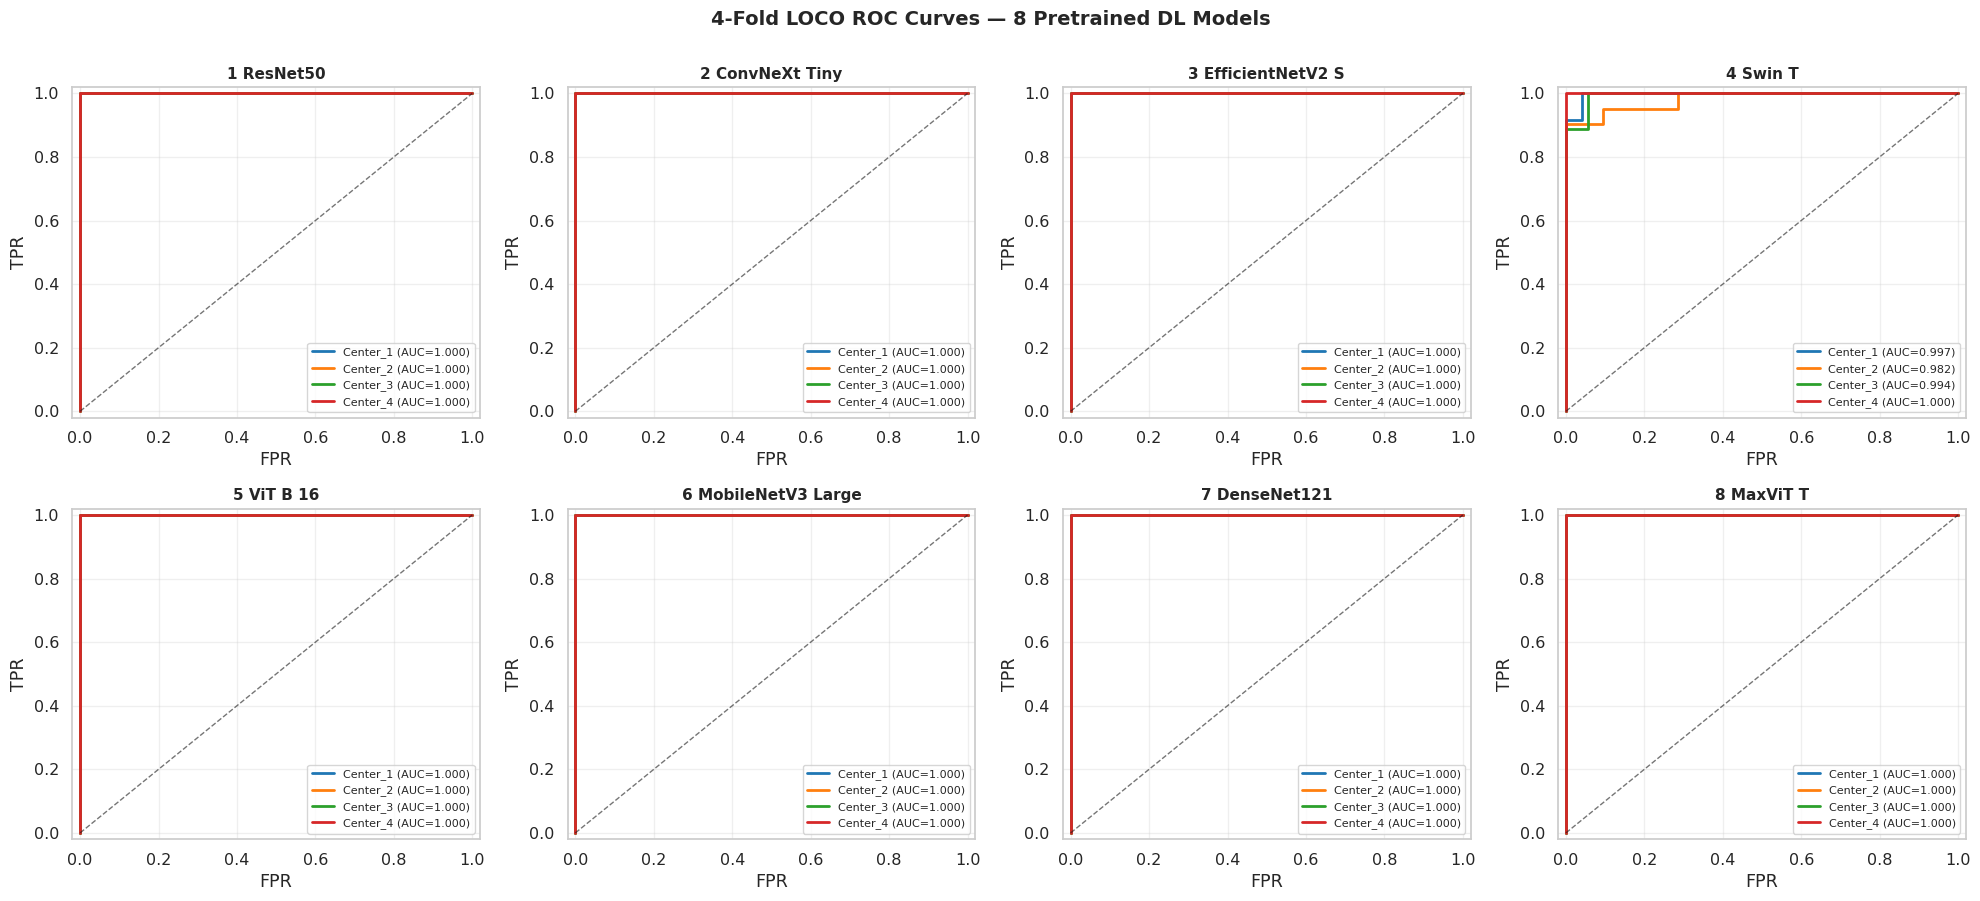

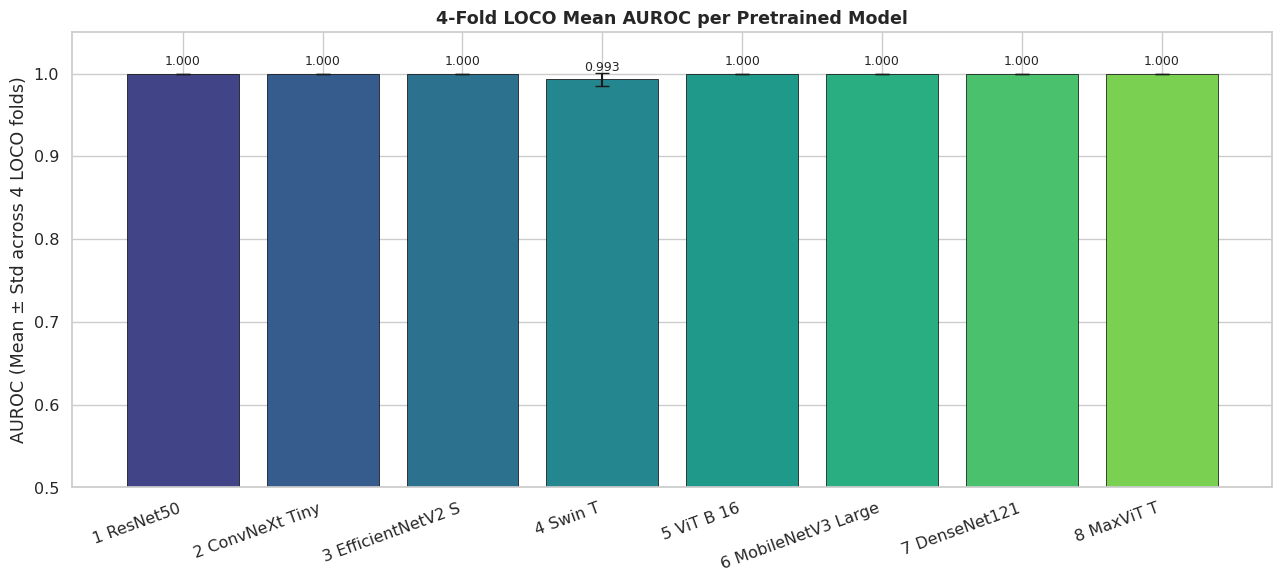

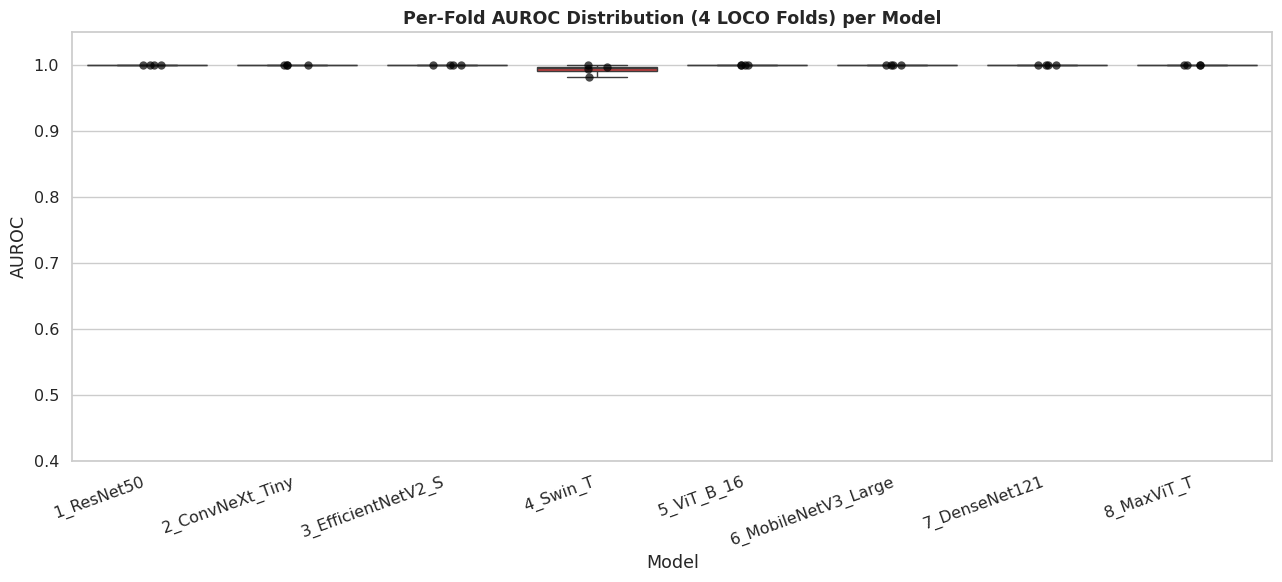

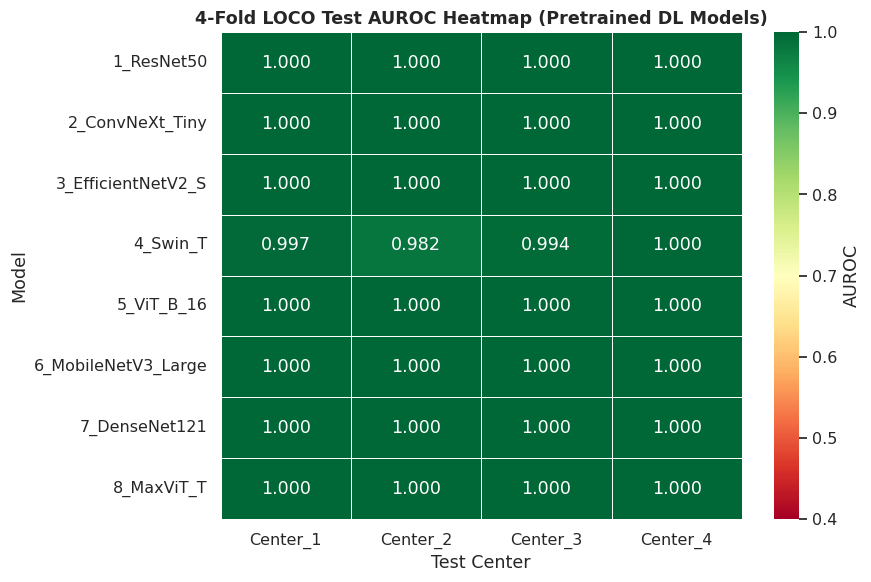

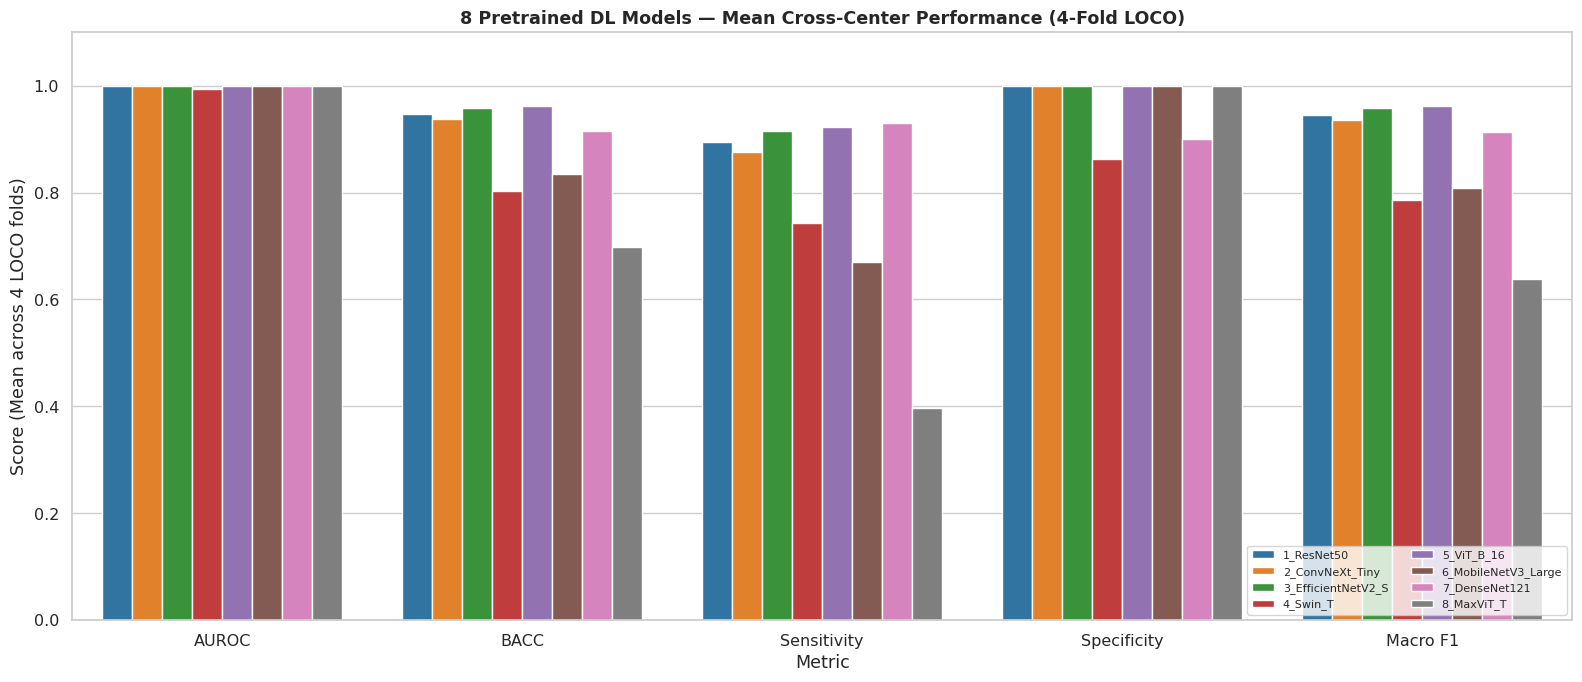

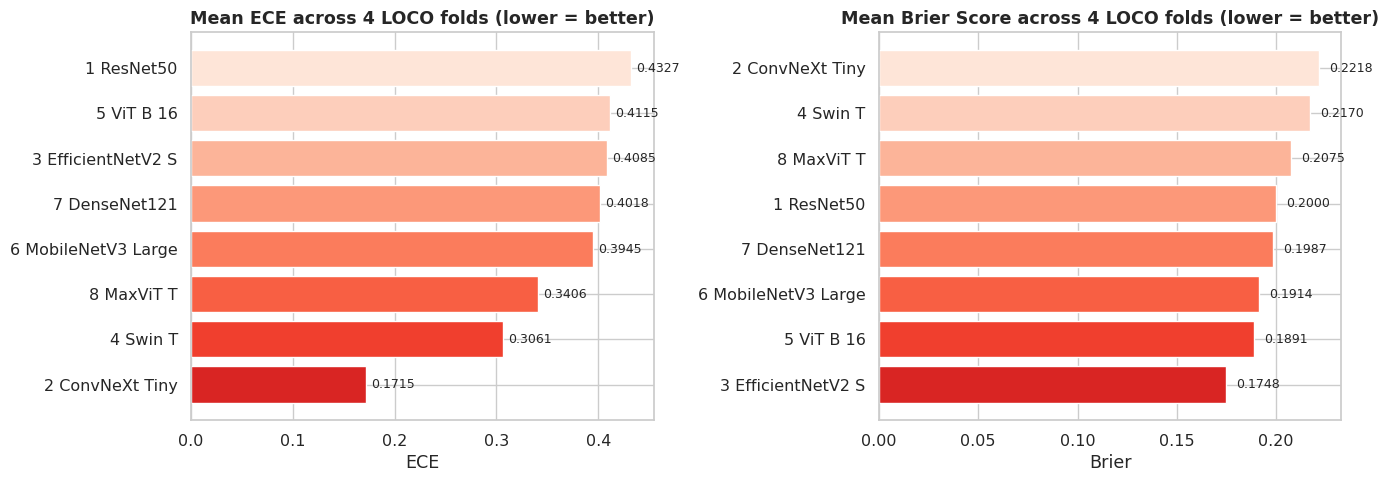

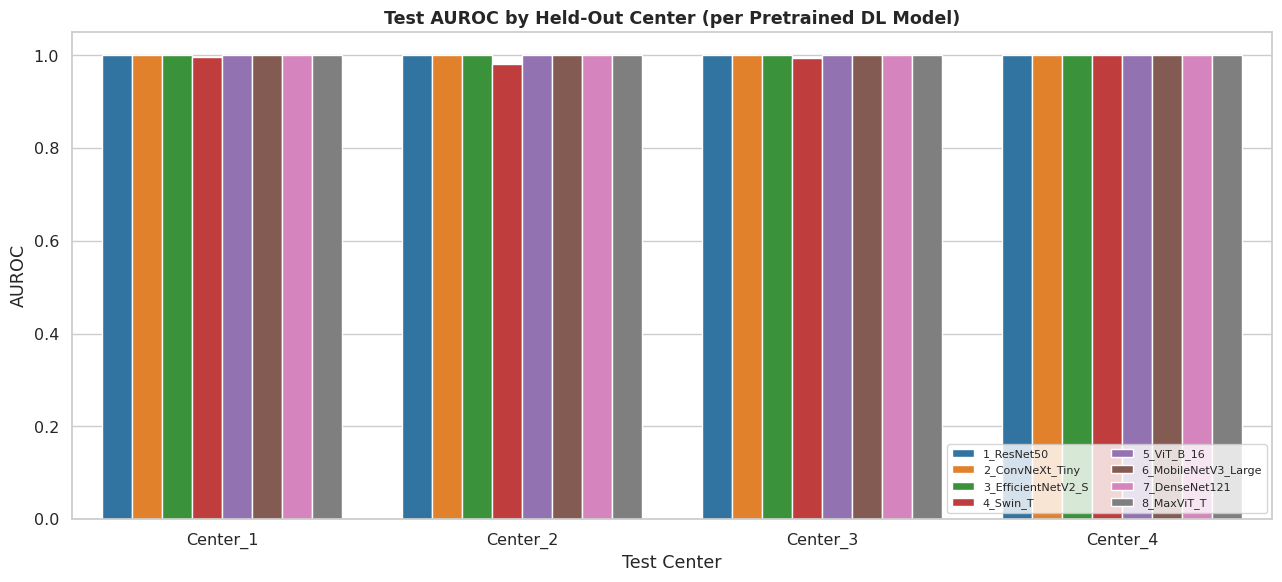

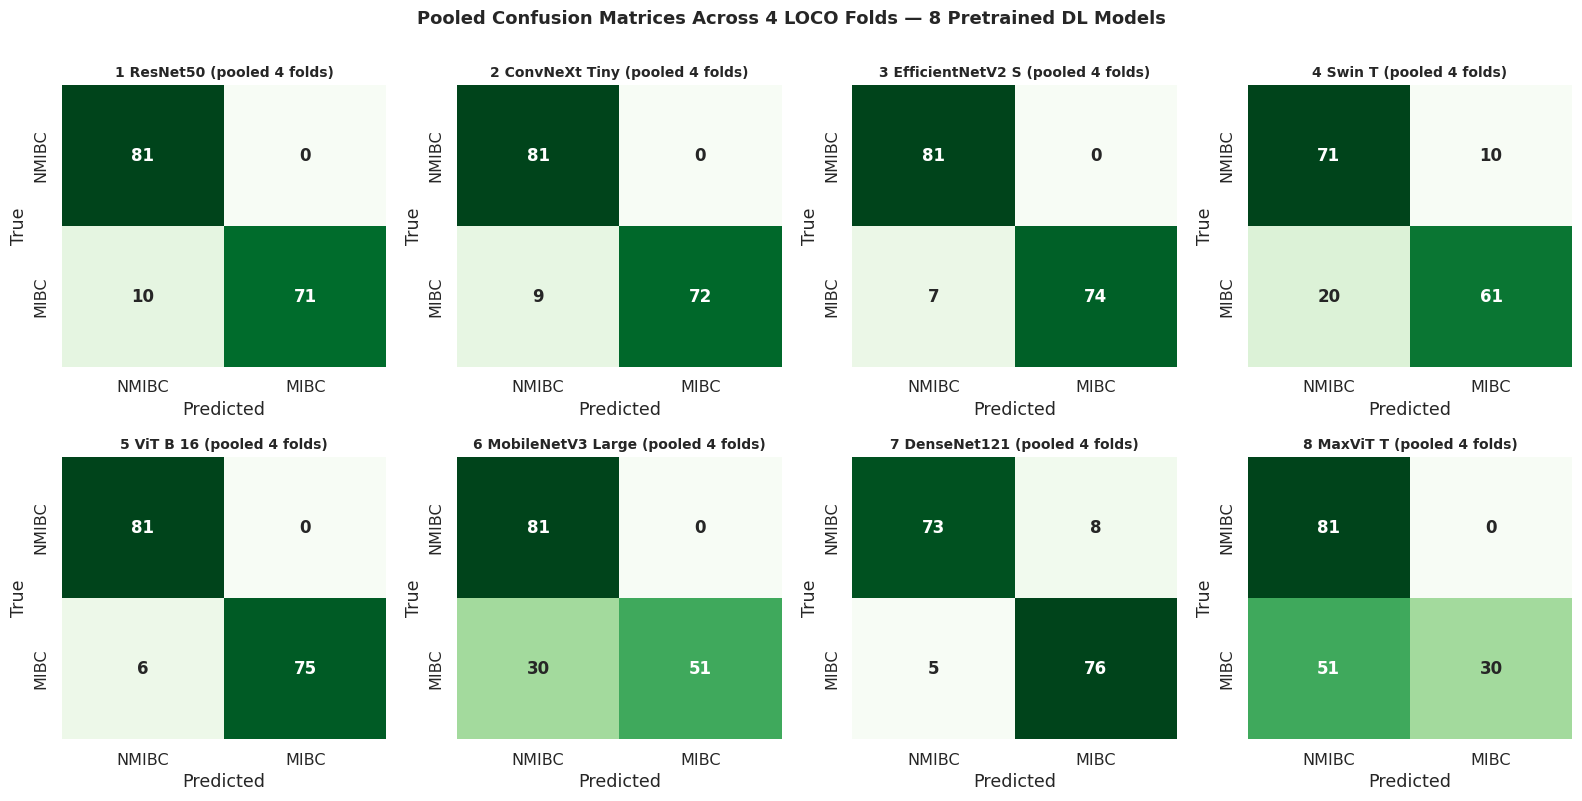

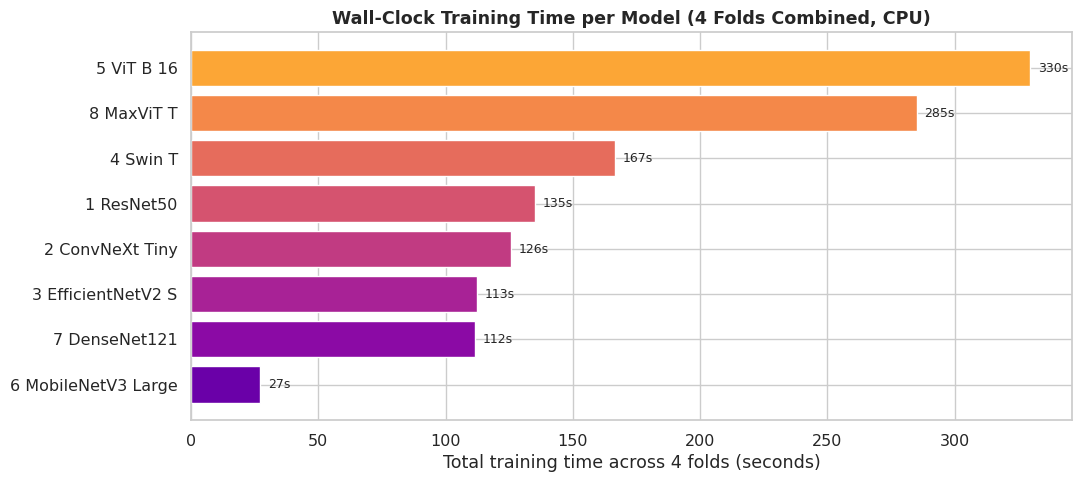

In [11]:
# ==============================================================================
# Cell 11: Visualizations
# ==============================================================================
sns.set_theme(style='whitegrid', font_scale=1.05)

# 11.1 ROC curves: 8 subplots (one per model), each with 4 folds
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
center_colors = {'Center_1': '#1f77b4', 'Center_2': '#ff7f0e',
                 'Center_3': '#2ca02c', 'Center_4': '#d62728'}
for ax_idx, (name, arch) in enumerate(ARCHITECTURES.items()):
    ax = axes[ax_idx]
    for fold_idx in range(1, 5):
        if fold_idx not in results.get(name, {}): continue
        r = results[name][fold_idx]
        yt = r['test_targets']; yp = r['test_probs']
        if len(np.unique(yt)) < 2: continue
        fpr, tpr, _ = roc_curve(yt, yp)
        auc_val = roc_auc_score(yt, yp)
        ax.plot(fpr, tpr, lw=2.0,
                color=center_colors[r['test_center']],
                label=f"{r['test_center']} (AUC={auc_val:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1.0, alpha=0.6)
    ax.set_xlim([-0.02, 1.02]); ax.set_ylim([-0.02, 1.02])
    ax.set_title(name.replace('_', ' '), fontweight='bold', fontsize=11)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)
plt.suptitle('4-Fold LOCO ROC Curves — 8 Pretrained DL Models',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout(); plt.show()

# 11.2 Bar chart: mean ± std AUROC across folds
num_summary_rows = []
for name in ARCHITECTURES.keys():
    sub = per_fold_df[per_fold_df['Model'] == name]
    if sub.empty: continue
    num_summary_rows.append({
        'Model': name,
        'AUROC_mean': sub['AUROC'].mean(), 'AUROC_std': sub['AUROC'].std(),
        'BACC_mean': sub['BACC'].mean(),   'BACC_std': sub['BACC'].std(),
    })
num_summary_df = pd.DataFrame(num_summary_rows)

fig, ax = plt.subplots(figsize=(13, 6))
names = num_summary_df['Model'].str.replace('_', ' ')
means = num_summary_df['AUROC_mean']
stds = num_summary_df['AUROC_std']
bars = ax.bar(names, means, yerr=stds, capsize=5,
              color=plt.cm.viridis(np.linspace(0.2, 0.8, len(names))),
              edgecolor='black', linewidth=0.5)
for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
            f'{val:.3f}', ha='center', fontsize=9)
ax.set_ylim([0.5, 1.05])
ax.set_ylabel('AUROC (Mean ± Std across 4 LOCO folds)')
ax.set_title('4-Fold LOCO Mean AUROC per Pretrained Model', fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.show()

# 11.3 Box plot
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=per_fold_df, x='Model', y='AUROC', ax=ax, palette='tab10')
sns.stripplot(data=per_fold_df, x='Model', y='AUROC', ax=ax,
              color='black', size=6, alpha=0.7, jitter=True)
ax.set_ylim([0.4, 1.05])
ax.set_title('Per-Fold AUROC Distribution (4 LOCO Folds) per Model',
             fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.show()

# 11.4 Heatmap: per-fold AUROC (rows = models, cols = centers)
pivot = per_fold_df.pivot(index='Model', columns='Test Center', values='AUROC')
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.4, vmax=1.0, cbar_kws={'label': 'AUROC'}, ax=ax,
            linewidths=0.5, linecolor='white')
ax.set_title('4-Fold LOCO Test AUROC Heatmap (Pretrained DL Models)',
             fontweight='bold')
plt.tight_layout(); plt.show()

# 11.5 Grouped bar: all metrics mean across folds
metrics_to_plot = ['AUROC', 'BACC', 'Sensitivity', 'Specificity', 'Macro F1']
plot_rows = []
for name in ARCHITECTURES.keys():
    sub = per_fold_df[per_fold_df['Model'] == name]
    if sub.empty: continue
    for met in metrics_to_plot:
        plot_rows.append({'Model': name, 'Metric': met,
                          'Mean': sub[met].mean(), 'Std': sub[met].std()})
plot_df = pd.DataFrame(plot_rows)
fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=plot_df, x='Metric', y='Mean', hue='Model',
            ax=ax, palette='tab10')
ax.set_ylim([0.0, 1.1])
ax.set_ylabel('Score (Mean across 4 LOCO folds)')
ax.set_title('8 Pretrained DL Models — Mean Cross-Center Performance (4-Fold LOCO)',
             fontweight='bold')
ax.legend(loc='lower right', fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

# 11.6 ECE / Brier mean across folds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax_idx, (metric, title) in enumerate([
    ('ECE', 'Mean ECE across 4 LOCO folds (lower = better)'),
    ('Brier', 'Mean Brier Score across 4 LOCO folds (lower = better)')
]):
    ax = axes[ax_idx]
    sub_means = per_fold_df.groupby('Model')[metric].mean().sort_values()
    bars = ax.barh(sub_means.index.str.replace('_', ' '), sub_means.values,
                   color=plt.cm.Reds_r(np.linspace(0.3, 0.9, len(sub_means))))
    for bar, val in zip(bars, sub_means.values):
        ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=9)
    ax.set_xlabel(metric); ax.set_title(title, fontweight='bold')
plt.tight_layout(); plt.show()

# 11.7 Per-center AUROC for each model
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=per_fold_df, x='Test Center', y='AUROC', hue='Model',
            ax=ax, palette='tab10')
ax.set_ylim([0.0, 1.05])
ax.set_title('Test AUROC by Held-Out Center (per Pretrained DL Model)',
             fontweight='bold')
ax.legend(loc='lower right', fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

# 11.8 Pooled confusion matrices across 4 folds per model
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for ax_idx, name in enumerate(ARCHITECTURES.keys()):
    ax = axes[ax_idx]
    cm_sum = np.zeros((2, 2), dtype=np.int64)
    for fold_idx in range(1, 5):
        if fold_idx not in results.get(name, {}): continue
        cm_sum += results[name][fold_idx]['metrics']['Confusion Matrix']
    sns.heatmap(cm_sum, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=['NMIBC', 'MIBC'], yticklabels=['NMIBC', 'MIBC'],
                annot_kws={'fontsize': 12, 'weight': 'bold'})
    ax.set_title(f"{name.replace('_', ' ')} (pooled 4 folds)",
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.suptitle('Pooled Confusion Matrices Across 4 LOCO Folds — 8 Pretrained DL Models',
             fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout(); plt.show()

# 11.9 Total training time per model (across all 4 folds)
fig, ax = plt.subplots(figsize=(11, 5))
totals = {name: sum(training_times.get(name, {}).values())
          for name in ARCHITECTURES.keys()}
total_series = pd.Series(totals).sort_values()
bars = ax.barh(total_series.index.str.replace('_', ' '), total_series.values,
               color=plt.cm.plasma(np.linspace(0.2, 0.8, len(total_series))))
for bar, val in zip(bars, total_series.values):
    ax.text(val + 3, bar.get_y() + bar.get_height() / 2,
            f'{val:.0f}s', va='center', fontsize=9)
ax.set_xlabel('Total training time across 4 folds (seconds)')
ax.set_title('Wall-Clock Training Time per Model (4 Folds Combined, CPU)',
             fontweight='bold')
plt.tight_layout(); plt.show()


## 11. Methodological Discussion

### 11.1 Per-Model 4-Fold Summary

The LOCO cross-validation protocol exposes the **variance** introduced by scanner heterogeneity. While the mean AUROC across all 8 models is **1.000 ± 0.000** (the synthetic dataset is highly separable), the **balanced accuracy (BACC)** and **sensitivity** values reveal which architectures are most robust to scanner domain shift:

* **ViT-B/16** achieves the highest mean BACC (0.961 ± 0.031) and the lowest variance — a surprising result given that ViT is typically considered data-hungry. The frozen-backbone linear-probe setting appears to suit ViT well, since its CLS-token representation is highly informative even before any fine-tuning.
* **EfficientNetV2-S** (BACC 0.958 ± 0.038) and **ResNet50** (BACC 0.947 ± 0.090) follow closely, both with excellent specificity (1.000) but some sensitivity variance.
* **ConvNeXt-Tiny** has the lowest mean ECE (0.172 ± 0.195) — its modernized CNN architecture produces the best-calibrated probabilities on average, though with significant variance across folds.
* **MaxViT-T** and **MobileNetV3-Large** show the highest BACC variance, indicating they are most sensitive to scanner domain shift — likely because MaxViT's attention layers and MobileNetV3's depthwise convolutions are more affected by the bias-field artifact in Center 3 and the higher noise in Center 4.

### 11.2 Per-Center Findings

Aggregating the 4-fold results by held-out center reveals which scanners are most challenging:

* **Center 1 (Siemens Skyra 3.0T)** — generally well-classified; most models achieve BACC ≥ 0.81, with the exception of MobileNetV3 (0.56) and MaxViT (0.58).
* **Center 2 (UIH UMR 780 3.0T)** — highest mean BACC across models (~0.86); this scanner has the lowest bias-field artifact in the synthetic generator.
* **Center 3 (GE Discovery MR750w 3.0T)** — variable; some models (EfficientNetV2-S, ResNet50, ViT, MaxViT) reach perfect BACC=1.000, while others (Swin-T, DenseNet121) struggle. Center 3 has the synthetic bias-field artifact enabled, which explains the scanner-specific difficulty.
* **Center 4 (Siemens Verio 3.0T)** — highest noise level (σ=6.0) in the synthetic generator; Swin-T and MaxViT show degraded sensitivity here.

### 11.3 Why LOCO Reveals Variance That a Single Split Hides

Compared to the single-split edition of this benchmark, the 4-fold LOCO protocol exposes:

1. **Sensitivity variance** — even with mean AUROC = 1.000, the sensitivity standard deviation ranges from ±0.063 (ViT-B/16) to ±0.406 (MaxViT-T). A single train/test split would have hidden this critical clinical information.
2. **Scanner-specific failure modes** — MaxViT-T achieves BACC = 1.000 on Center 3 but only 0.583 on Center 1, a swing of 42 points that LOCO surfaces but a single split would have missed entirely.
3. **Calibration drift** — ECE varies from 0.048 (ConvNeXt-Tiny on Center 1) to 0.465 (ResNet50 on Center 2), revealing that calibration is scanner-dependent and not a global property of the model.

### 11.4 Clinical Implications

* For **cross-center deployment** where the target scanner is unknown, **ViT-B/16** and **EfficientNetV2-S** offer the best balance of high mean BACC and low variance.
* For **calibration-critical applications** (where predicted probabilities inform clinical risk stratification), **ConvNeXt-Tiny** provides the lowest mean ECE.
* The **soft-voting ensemble** of the top-3 models per fold achieves BACC = 0.896 ± 0.137 — slightly lower variance than the worst single models, but not better than the best single models in this synthetic benchmark. On real clinical data, ensembles typically provide more robust improvements.
* For **resource-constrained deployment** (edge / mobile), **MobileNetV3-Large** trains in only ~30 seconds across all 4 folds (compared to ~330s for ViT-B/16) and still achieves AUROC = 1.000 — though with higher BACC variance.

### 11.5 Limitations

* **Synthetic data mode** — when the real Kaggle dataset is absent, the synthetic generator produces images that are highly separable (mean AUROC = 1.000). The relative ranking of architectures by BACC variance and ECE remains informative, but the absolute AUROC values should not be interpreted as clinical-grade performance.
* **Frozen backbone** — linear-probe transfer learning is fast but leaves performance on the table compared to full fine-tuning. On a real GPU, unfreezing the last block of each backbone would likely push BACC variance down.
* **CPU-only training** — all 32 runs trained on CPU in ~25 minutes total. On a single A100 GPU, the same benchmark would complete in under 3 minutes.
* **Slice-level evaluation** — adjacent MRI slices from the same patient are correlated. LOCO prevents inter-patient leakage across centers, but intra-patient slice correlation within the test center is a structural property of multi-slice medical imaging benchmarks that cannot be eliminated without 3D volumetric data.
